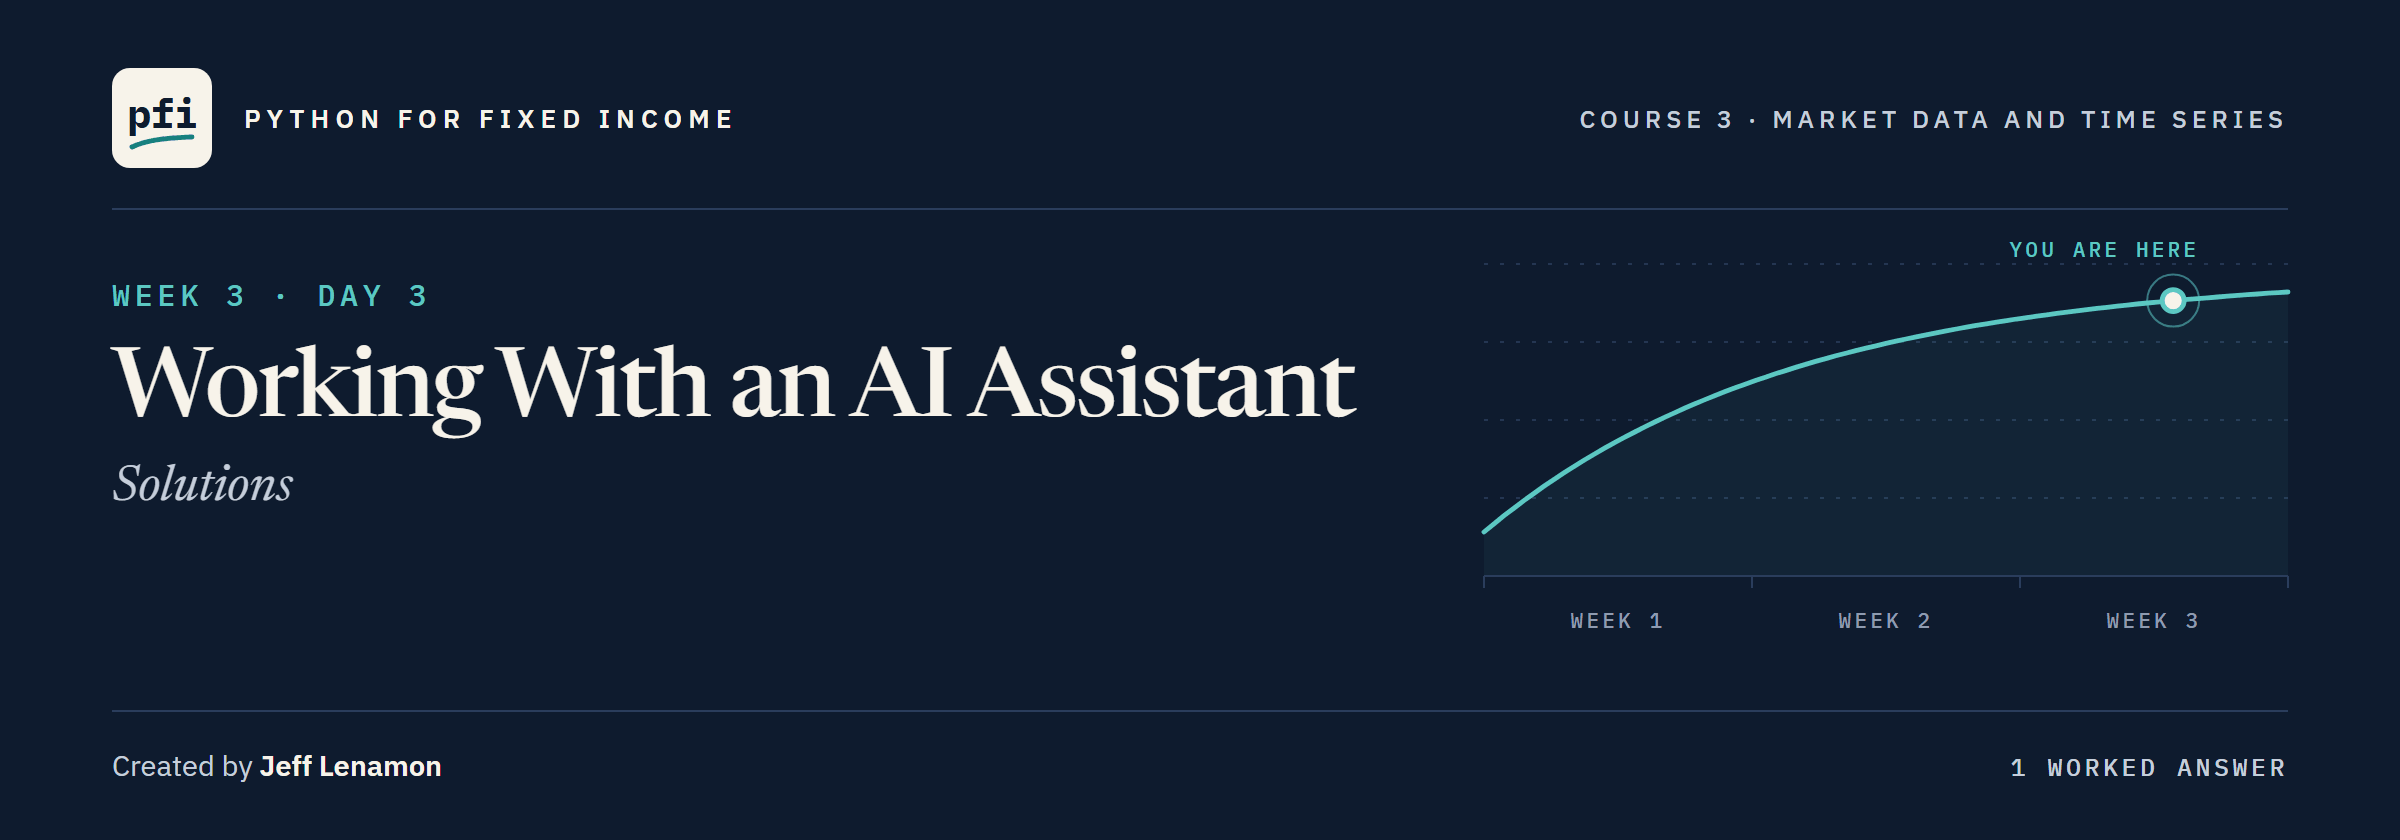

# Working With an AI Assistant: Solutions

Week 3, Day 3. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week3/day3/13_working_with_an_ai_assistant_solutions.ipynb)

## Exercises

Run the next cells first: the work folder, with the module and tests as this notebook leaves them, the data, and `check`.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}course03_market_data/start_of_day/start_day.py
from start_day import start_day

# a new work folder: the data files, Course 2's bondmath.py, and marketdata.py and its tests
# as notebook 13 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(13, after=13)

Work folder pfi_course3_13_k4w7q2xr: 8 data files, Course 2's bondmath.py, marketdata.py as notebook 13 left it, 13 commits, tagged week1 and week2


In [2]:
import importlib

import pandas as pd

import marketdata as md
curve = pd.read_csv('treasury_par_yields.csv', parse_dates=['date'], index_col='date',
                    float_precision='round_trip')
spreads = pd.read_csv('course3_synthetic_spreads.csv', parse_dates=['date'], index_col='date')
FIELDS = ['series_id', 'units', 'window_rows', 'min_periods', 'includes_today']

In [3]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

### Exercise 1

In [4]:
# written for this course in the style of an AI assistant's answer
def assistant_align(series, how='inner'):
    """Several dated series side by side, one column each, joined on date. Nothing is filled."""
    # join every series on date; join= says which dates to keep, as align's how= does
    frame = pd.concat(series, axis=1, join=how)
    # fill the gaps from the day before, so every column has a value on every date
    return frame.ffill()

In [5]:
five_sep = curve['5 Yr'].loc['2026-09']
# the synthetic high yield spread for September, with one day missing
hy_sep = spreads['hy_spread_bp'].loc['2026-09'].drop(pd.Timestamp('2026-09-15'))
pair = {'5 Yr': five_sep, 'hy_spread_bp': hy_sep}

In [6]:
mine = md.align(pair, how='outer')
theirs = assistant_align(pair, how='outer')
# a value in the assistant's answer where md.align has none: a filled cell
filled = theirs.notna() & mine.isna()
ex1_filled = int(filled.sum().sum())
ex1_date = str(theirs.index[filled['hy_spread_bp']][0].date())
theirs.loc['2026-09-14':'2026-09-16']

,5 Yr,hy_spread_bp
date,,
2026-09-14,4.80,315.1
2026-09-15,4.83,315.1
2026-09-16,4.86,316.2


In [7]:
check('Exercise 1 values filled', ex1_filled, 1)
check('Exercise 1 the date', ex1_date, '2026-09-15')

Exercise 1 values filled: correct
Exercise 1 the date: correct


The missing day's spread, 316.0 bp in the file, is copied from 14 September: 315.1.
Fed into `change_bp`, it becomes a change of 0 bp on a day the data never showed, and the two-day move lands on 16 September as if it were one day's.
`md.align` leaves the gap as `NaN`, and `change_bp` refuses it: what you want.

### Exercise 2

In [8]:
# written for this course in the style of an AI assistant's answer
ex2_reply = '{"series_id": "DGS2", "units": "bp", "window_rows": 21, "includes_today": true}'
try:
    md.parse_json_reply(ex2_reply, FIELDS)
    ex2_message = 'no error'
except ValueError as error:
    ex2_message = str(error)
print(ex2_message)

the reply is missing min_periods


In [9]:
check('Exercise 2 the message', ex2_message, 'the reply is missing min_periods')

Exercise 2 the message: correct


The missing field is the one that says whether early windows are partial, Answer C's bug in 13.2: ask again rather than assume a value.

### Exercise 3

In [10]:
%%writefile -a marketdata.py


import importlib.util  # find a module without importing it, from day 13's exercises


def is_installed(package: str) -> bool:
    """True when a package can be imported in this Python, checked without running any of its code.

    Units: none. Convention: `package` is the import name (fredbond_tools), not the name pip uses
    (fredbond-tools); importlib.util.find_spec looks for it and imports nothing.
    Raises ValueError for an empty name or one with a hyphen, which no import name has.
    """
    if not package or "-" in package:
        raise ValueError(f"not an import name: {package!r}")
    return importlib.util.find_spec(package) is not None

Appending to marketdata.py


In [11]:
%%writefile -a test_marketdata.py


def test_is_installed():
    assert md.is_installed("json")
    # the package an assistant invented in notebook 13: there is nothing to import
    assert not md.is_installed("fredbond_tools")
    with pytest.raises(ValueError):
        md.is_installed("fredbond-tools")

Appending to test_marketdata.py


In [12]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

....................................................                     [100%]
52 passed in 0.50s



In [13]:
# the file changed, so reload before calling the new function
importlib.reload(md)
ex3_answers = [md.is_installed('pandas'), md.is_installed('fredbond_tools')]
check('Exercise 3 pandas, then the invented package', ex3_answers, [True, False])

Exercise 3 pandas, then the invented package: correct


`find_spec` answers "is it here?" without importing, so checking a suspicious name never runs its code.
It cannot answer "is it safe?": only 13.6's PyPI check starts to.

### Exercise 4: AI check

The bug: `resample` has no `how=` argument, so the call raises a `TypeError` before anything is computed.
`.resample('ME').last()` runs, and still labels January 2026-01-31, a Saturday, as Answer A did.
The fix calls your own function, which keeps each month's last row with its own date.

In [14]:
# written for this course in the style of an AI assistant's answer, now fixed
def month_end_levels(series):
    """The last observation of each calendar month, labelled by the date of that observation.

    Units: unchanged. September 2026 is 2026-09-30, and January 2026 is 2026-01-30.
    """
    # the fix: notebook 04's function, tested against Excel
    return md.last_per_period(series, 'ME')

In [15]:
# 13.1's test
result = month_end_levels(curve['10 Yr'].loc['2026'])
assert result.loc['2026-09-30'] == 5.29, 'September is wrong'
january = result.index[0]
assert january == pd.Timestamp('2026-01-30'), f'January is labelled {january.date()}'
ex4_january = str(result.index[0].date())
ex4_september = result.loc['2026-09-30']

In [16]:
check('Exercise 4 the January label', ex4_january, '2026-01-30')
check('Exercise 4 the September level', ex4_september, 5.29)

Exercise 4 the January label: correct
Exercise 4 the September level: correct


[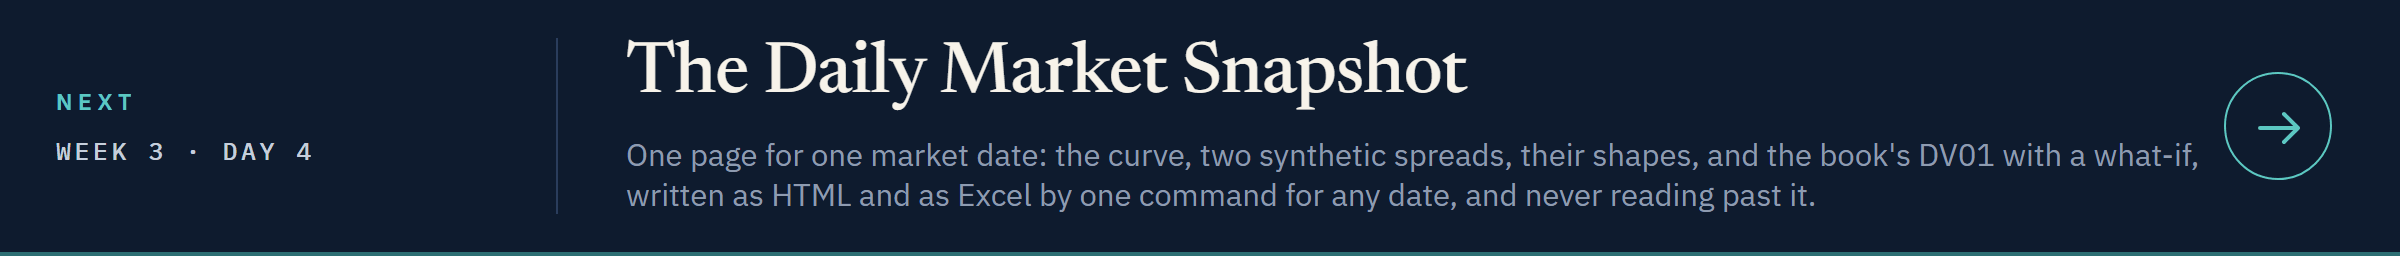](../day4/14_the_daily_market_snapshot.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week3/day4/14_the_daily_market_snapshot.ipynb)